## MobileNet 개요
- 개념: 2017년 구글(Andrew G. Howard 등)이 발표한 경량화 딥러닝 모델 아키텍처
- 목적: 자원이 제한된 모바일·임베디드 기기에서 실시간 추론이 가능하도록 연산량(FLOPs)과 파라미터 수 최소화

## 핵심 메커니즘: Depthwise Separable Convolution
- 2단계 분리 연산 구조
  - 1단계 (Depthwise Conv): 3x3 커널로 각 입력 채널별 공간(Spatial) 정보만 독립 추출 (채널간 섞임 없음)
  - 2단계 (Pointwise Conv): 1x1 커널로 채널(Cross-Channel) 정보를 결합하여 출력 채널 수 조절
- 연산량 절감 효과
  - 연산비율: 1/D_out + 1/K^2 (K: 커널 크기, D_out: 출력 채널 수)
  - 절감 수치: 3x3 커널 기준, 일반 Convolution 대비 연산량·파라미터 약 1/9 수준으로 감소 (80~90% 감축)
- 핵심 이점: 높은 정확도를 유지하면서 컴퓨팅 파워가 부족한 온디바이스(On-Device) 환경에서 실시간 동작 가능

<img src="https://blog.kakaocdn.net/dna/bGRRYD/btszLusiETk/AAAAAAAAAAAAAAAAAAAAAAQAxf_Fw_6AH1dFS48itdbZGNyxcN3uT-AydADUrNVR/img.png?credential=yqXZFxpELC7KVnFOS48ylbz2pIh7yKj8&expires=1793458799&allow_ip=&allow_referer=&signature=On3xCEHP3qAjA9QT8ntgDWioAlg%3D" />

In [2]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

from kaggle.api.kaggle_api_extended import KaggleApi

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()
# 오류 발생시
# sklearn.set_config(display="text")

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token


True

# Food-11 데이터셋
- 빵, 디저트, 면류, 육류 등 일상에서 흔히 접하는 11가지 주요 음식 카테고리로 구성된 표준 이미지 분류 데이터셋입니다.
다양한 조리 방식과 재료 특성으로 인해 음식 간 시각적 유사성이 높아, 모델의 세밀한 특징 추출 및 다중 클래스 분류 능력을 검증하기에 최적입니다.
복잡한 시각적 패턴을 가진 도메인에서 전이학습(Feature Extraction) 파이프라인 구현과 오분류 분석 역량을 평가하는 데 효과적으로 활용될 수 있습니다.

[food11 데이터셋 링크](https://www.kaggle.com/datasets/trolukovich/food11-image-dataset)

In [3]:
base_path = r"D:\kdt_dataset\machine_learning"

In [4]:
api = KaggleApi()
api.authenticate()

output_dir = r"D:\kdt_dataset\machine_learning\food11"
os.makedirs(output_dir, exist_ok=True)
# api.dataset_download_files(r"trolukovich/food11-image-dataset", path=output_dir, unzip=True)

print("다운로드 완료")

다운로드 완료


https://docs.pytorch.org/vision/main/models/generated/torchvision.models.mobilenet_v2.html#torchvision.models.mobilenet_v2

In [5]:
train_path = os.path.join(base_path, r"food11", r"training")
val_path = os.path.join(base_path, r"food11", r"validation")
test_path = os.path.join(base_path, r"food11", r"evaluation")

In [6]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [7]:
train_dataset = ImageFolder(train_path, transform=train_transform)
val_dataset = ImageFolder(val_path, transform=test_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

In [8]:
len(train_dataset), len(val_dataset), len(test_dataset)

(9866, 3430, 3347)

In [9]:
# num_workers=2(CPU 코어 개수)
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
val_dataloader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

In [10]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: xpu


In [11]:
model_weights_path = os.path.join(base_path, "weights")
os.makedirs(model_weights_path, exist_ok=True)

# PyTorch Hub 기본 캐시 경로를 변경
torch.hub.set_dir(model_weights_path)

model_mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT).to(device)

## 모델 프리징

In [12]:
for param in model_mobilenet.parameters():
    param.requires_grad = False

In [13]:
model_mobilenet.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(model_mobilenet.classifier[1].in_features, 256),
    nn.BatchNorm1d(256), # 가중치 안정화(선택사항)
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 11)
)

In [14]:
model_mobilenet = model_mobilenet.to(device)

In [15]:
model_mobilenet

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [16]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device):
    model.train()
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        batch_loss = 0.0
        
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] | [Batch Loss: {batch_loss:.4f}] | [Batch Accuracy: {acc:.2f}]")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [17]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [18]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {
        "train_loss": [], 
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }
    best_val_acc = 0.0

    # 학습
    print(f"===================== {model_name} 학습 시작 =====================")
    for epoch in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}")
        print(f"[Epoch: {epoch + 1}/{epochs}] | Vaildation Loss: {val_loss:.4f} | Vaildation Accuracy: {val_acc:.2f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"===================== {model_name} 학습 종료 =====================")
    return history

In [19]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_mobilenet.classifier.parameters(), lr=0.001)

## 전이학습 속도 개선(개인적으로 한 것)

In [ ]:
# ===== 전이학습 속도 개선: 백본 특징 벡터 캐싱 =====
# model_mobilenet의 백본이 전부 얼려져 있으므로(셀 14) 같은 입력에서 항상 같은 특징이 나온다.
# 매 에폭마다 MobileNetV2 forward를 반복할 이유가 없으니 한 번만 뽑아 재사용한다.
import time

# 1) 특징 추출용 로더 - 증강 없는 test_transform 사용
#    RandomResizedCrop / RandomHorizontalFlip / RandomRotation이 섞이면
#    캐시가 한 가지 변형에 고정되므로 제외한다
extract_train_loader = DataLoader(
    ImageFolder(train_path, transform=test_transform),
    batch_size=64, shuffle=False, num_workers=2
)
extract_val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)

# 2) MobileNetV2는 ResNet과 구조가 달라서 children()[:-1] 방식을 쓸 수 없다.
#    forward가 features -> adaptive_avg_pool2d -> flatten -> classifier 순서인데
#    pooling이 자식 모듈이 아니라 forward 코드 안에 들어 있기 때문이다.
#    features만 통과시키면 (N, 1280, 7, 7)이므로 pooling을 직접 해줘야 (N, 1280)이 된다.
backbone = model_mobilenet.features
backbone.eval()   # 얼린 BatchNorm의 running stats가 현재 배치 통계로 덮어써지는 것을 막는다

@torch.no_grad()
def extract_features(dataloader, tag):
    feats, labels = [], []
    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        x = backbone(X_batch.to(device))                   # (B, 1280, 7, 7)
        x = F.adaptive_avg_pool2d(x, (1, 1)).flatten(1)    # (B, 1280)
        feats.append(x.cpu())
        labels.append(y_batch)
        if i % 20 == 0:
            print(f"  [{tag}] {i}/{len(dataloader)}")
    return torch.cat(feats), torch.cat(labels)

t0 = time.time()
print("train 특징 추출 중...")
train_feat, train_lab = extract_features(extract_train_loader, "train")
print("validation 특징 추출 중...")
val_feat, val_lab = extract_features(extract_val_loader, "val")

print(f"\n추출 완료: {time.time() - t0:.1f}초")
print(f"  train {tuple(train_feat.shape)} / val {tuple(val_feat.shape)}")
cache_mb = (train_feat.numel() + val_feat.numel()) * 4 / 1024 ** 2
print(f"  캐시 메모리: {cache_mb:.1f} MB")

# 3) 1280차원 벡터 데이터셋 - 이제 디스크 접근도 conv 연산도 없다
feat_train_loader = DataLoader(TensorDataset(train_feat, train_lab), batch_size=256, shuffle=True)
feat_val_loader = DataLoader(TensorDataset(val_feat, val_lab), batch_size=256)

# 4) 학습할 헤드만 준비 (셀 15의 classifier와 완전히 같은 구조)
in_features = train_feat.size(1)              # 1280
num_classes = len(train_dataset.classes)      # 11
head = nn.Sequential(
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(in_features, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, num_classes)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer_head = optim.Adam(head.parameters(), lr=0.001)

# 학습이 끝난 뒤 전체 모델로 추론하려면 가중치를 되돌려 넣으면 된다
#   model_mobilenet.classifier.load_state_dict(head.state_dict())
print("\n다음 셀 인자를 이렇게 바꿔서 실행하세요:")
print("  model=head, train_loader=feat_train_loader,")
print("  val_loader=feat_val_loader, optimizer=optimizer_head")

In [ ]:
history = train_model_multiclass(
    model=model_mobilenet,                      
    model_name="Mobilenet-multiclass",
    train_loader=train_dataloader,  
    val_loader=val_dataloader,     
    criterion=criterion,
    optimizer=optimizer,        
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path, r"food11")
)

## 모델 평가

In [ ]:
best_model_path = os.path.join(base_path, r"food11", r"Mobilenet-multiclass", r"best_model.pth")
best_model_path

In [ ]:
model_mobilenet.load_state_dict(torch.load(best_model_path))
model_mobilenet = model_mobilenet.to(device)

In [ ]:
model_mobilenet.eval()

test_loss, test_acc = evaluate_multiclass(
    model=model_mobilenet, 
    dataloader=test_dataloader, 
    criterion=criterion, 
    device=device
)

print("최종 모델의 평가")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}")

## 예측 시각화

In [ ]:
imgs, labels = next(iter(test_dataloader))

In [ ]:
class_to_idx = train_dataset.class_to_idx
class_dict = dict(enumerate(train_dataset.classes))

In [ ]:
model_mobilenet.eval()
imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model_mobilenet(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

mean = np.array(mean)
std = np.array(std)

for ax, img, label, pred in zip(axes.flatten(), imgs, labels, pred_labels):
    img_np = img.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np * std + mean, 0, 1)
    true_label = int(label.item())
    pred_label = int(pred.item())
    color = "green" if true_label == pred_label else "red"
    ax.imshow(img_np)
    ax.set_title(f"True: {class_dict[true_label]}\nPred: {class_dict[pred_label]}", color=color)
    ax.axis("off")

plt.show()

## 틀린 이미지 출력하기

In [ ]:
model_mobilenet.eval()
imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model_mobilenet(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()

incorrect_samples = []
incorrect_mask = (pred_labels != labels)

if incorrect_mask.any():
    for img, label, pred in zip(imgs[incorrect_mask], labels[incorrect_mask], pred_labels[incorrect_mask]):
        incorrect_samples.append({
            "img": img,
            "true_label": label.item(),
            "pred_label": pred.item()
        })

print(incorrect_samples)

## UTKFace 데이터셋
- UTKFace 데이터셋(UTKFace Dataset)은 컴퓨터 비전 및 머신러닝 분야에서 얼굴 이미지를 기반으로 한 연령 예측(Age Estimation), 성별 분류, 인종 분류 및 얼굴 분석 알고리즘 연구에 널리 활용되는 대표적인 벤치마크 데이터셋입니다.
- 수량 및 해상도: 다양한 연령대와 배경을 가진 사람들의 얼굴 이미지 약 20,000장 이상으로 구성되어 있습니다.
- 라벨 정보: 각 이미지에는 나이(0세부터 116세까지의 연속된 정수/실수), 성별(남성/여성), 인종(백인, 흑인, 아시안, 인도인, 기타) 레이블이 세밀하게 부여되어 있습니다.
- 파일명 자가 라벨링 규칙: 메타데이터 파일(CSV)을 별도로 관리하지 않고, [나이]_[성별]_[인종]_[생성일시].jpg 형태의 고유한 파일명 규칙을 따릅니다. 이를 통해 복잡한 데이터 조인 과정 없이 파일명 문자열 파싱만으로 타겟 레이블을 손쉽게 추출할 수 있습니다.

[UTKFace 공식문서](https://www.kaggle.com/datasets/jangedoo/utkface-new)

In [20]:
utk_path = os.path.join(base_path, "utkface")
os.makedirs(utk_path, exist_ok=True)

api = KaggleApi()
api.authenticate()
# api.dataset_download_files(r"jangedoo/utkface-new", path=utk_path, unzip=True)

print("다운로드 완료")

다운로드 완료


In [21]:
import glob
utk_img_path = os.path.join(utk_path, r"UTKFace")

all_files = glob.glob(os.path.join(utk_img_path, "*.jpg"))

In [22]:
len(all_files)

23708

In [23]:
train_datas, temp_datas = train_test_split(all_files, test_size=0.2, random_state=42)
val_datas, test_datas = train_test_split(temp_datas, test_size=0.5, random_state=42)

len(train_datas), len(val_datas), len(test_datas)

(18966, 11854, 11854)

In [24]:
class UTKFaceDataset(Dataset):
    def __init__(self, file_paths, transform=None):
        self.file_paths = file_paths
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        image = Image.open(img_path).convert("RGB")

        file_name = os.path.basename(img_path)
        age = float(file_name.split("_")[0])

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor([age], dtype=torch.float32)

In [25]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [26]:
train_dataset = UTKFaceDataset(train_datas, transform=train_transform)
val_dataset = UTKFaceDataset(val_datas, transform=test_transform)
test_dataset = UTKFaceDataset(test_datas, transform=test_transform)

In [27]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [28]:
imgs, labels = next(iter(train_dataloader))
imgs.size(), labels.size()

(torch.Size([32, 3, 224, 224]), torch.Size([32, 1]))

In [29]:
model2 = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model2

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [30]:
for param in model2.parameters():
    param.requires_grad = False

In [31]:
in_features = model2.classifier[1].in_features
model2.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(1280, 128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 1)  # 분류가 아닌 회귀 모델이므로 최종적으로 출력값을 1개만 내보냄
)

In [32]:
model2 = model2.to(device)

### AdamW (Adam with Decoupled Weight Decay)
- AdamW는 기존 Adam의 가중치 감쇠(Weight Decay) 연산 방식을 개선하여 모델의 일반화 성능을 높인 최적화 알고리즘입니다.

#### 핵심 특징
- Weight Decay 분리 (Decoupling): 기존 Adam은 가중치 감쇠가 기울기(Gradient) 계산에 얽혀 모멘텀을 왜곡했으나, AdamW는 이를 완전히 분리하여 순수 기울기로만 모멘텀을 계산하고 가중치 감쇠는 별도로 적용합니다.
- 과적합 방지 및 일반화: Adam의 빠른 수렴 속도를 유지하면서, 전이학습(Transfer Learning) 시 사전 학습된 가중치의 과적합을 효과적으로 억제합니다.

#### 주요 하이퍼파라미터
- params: model.parameters()
  최적화할 모델의 가중치 패러미터 집합
- lr: 1e-4 ~ 3e-4
  학습률 (Learning Rate): 매 스텝 가중치 업데이트 크기 (전이학습 시 1e-4 이하 권장)
- weight_decay: 1e-2 (0.01)
  가중치 감쇠: 가중치가 과도하게 커지는 것을 방지하는 정규화(Regularization) 계수
- betas: (0.9, 0.999)
  모멘텀 계수 (beta1, beta2): beta1(1차 기울기 관성), beta2(2차 기울기 제곱 보폭) 지수 이동 평균 비율
- eps: 1e-8
  수치 안정성 상수 (epsilon): 0으로 나누는 연산 오류 방지용 미소값

In [33]:
criterion = nn.L1Loss() # 절대값 오차(MAE)
optimizer2 = optim.AdamW(model2.classifier.parameters(), lr=1e-4, weight_decay=1e-2)

In [34]:
def train_one_epoch_regression(model, dataloader, criterion, optimizer, device):
    model.train()
    sum_losses = 0.0
    sum_maes = 0.0
    sum_mses = 0.0
    sum_rmses = 0.0
    
    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 회귀의 잔차 계산
        preds_flat = y_pred.squeeze()
        targets_flat = y_batch.squeeze()

        mae = torch.abs(preds_flat - targets_flat).mean().item()
        mse = ((preds_flat - targets_flat) ** 2).mean().item()
        rmse = torch.sqrt(torch.tensor(mse)).item()

        sum_maes += mae
        sum_mses += mse
        sum_rmses += rmse

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, MAE: {mae:.2f}, MSE: {mse:.2f}, RMSE: {rmse:.2f}")

    length = len(dataloader)
    avg_loss = sum_losses / length
    avg_mae = sum_maes / length
    avg_mse = sum_mses / length
    avg_rmse = sum_rmses / length

    return avg_loss, avg_mae, avg_mse, avg_rmse

In [35]:
@torch.no_grad()
def evaluate_regression(model, dataloader, criterion, device):
    model.eval()
    sum_losses = 0.0
    sum_maes = 0.0
    sum_mses = 0.0
    sum_rmses = 0.0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 회귀의 잔차 계산
        preds_flat = y_pred.squeeze()
        targets_flat = y_batch.squeeze()

        mae = torch.abs(preds_flat - targets_flat).mean().item()
        mse = ((preds_flat - targets_flat) ** 2).mean().item()
        rmse = torch.sqrt(torch.tensor(mse)).item()

        sum_maes += mae
        sum_mses += mse
        sum_rmses += rmse

    length = len(dataloader)
    avg_loss = sum_losses / length
    avg_mae = sum_maes / length
    avg_mse = sum_mses / length
    avg_rmse = sum_rmses / length

    return avg_loss, avg_mae, avg_mse, avg_rmse

In [36]:
def train_model_regression(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {
        "train_loss": [], "val_loss": [], 
        "train_mae": [], "val_mae": [], 
        "train_mse": [], "val_mse": [], 
        "train_rmse": [], "val_rmse": []
    }
    best_val_loss = 0.0

    # 학습
    print(f"===================== {model_name} 학습 시작 =====================")
    for epoch in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_mae, train_mse, train_rmse = train_one_epoch_regression(model, train_loader, criterion, optimizer, device)
        val_loss, val_mae, val_mse, val_rmse = evaluate_regression(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}/{epochs}] | Train Loss: {train_loss:.4f} | MAE: {train_mae:.2f} | MSE: {train_mse:.2f} | RMSE: {train_rmse:.2f}")
        print(f"[Epoch: {epoch + 1}/{epochs}] | Vaildation Loss: {val_loss:.4f} | MAE: {val_mae:.2f} | MSE: {val_mse:.2f} | RMSE: {val_rmse:.2f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)
        history["train_mse"].append(train_mse)
        history["val_mse"].append(val_mse)
        history["train_rmse"].append(train_rmse)
        history["val_rmse"].append(val_rmse)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"===================== {model_name} 학습 종료 =====================")
    return history

In [37]:
history2 = train_model_regression(
    model=model2,
    model_name="Mobilenet-regression",
    train_loader=train_dataloader,
    val_loader=val_dataloader,
    criterion=criterion,
    optimizer=optimizer2,
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path, "utkface")
)

===================== Mobilenet-regression 학습 시작 =====================
[Batch 20/593] Batch Loss: 34.2289, MAE: 34.23, MSE: 1558.93, RMSE: 39.48
[Batch 40/593] Batch Loss: 29.0910, MAE: 29.09, MSE: 1282.14, RMSE: 35.81
[Batch 60/593] Batch Loss: 33.5066, MAE: 33.51, MSE: 1803.57, RMSE: 42.47
[Batch 80/593] Batch Loss: 32.4886, MAE: 32.49, MSE: 1469.71, RMSE: 38.34
[Batch 100/593] Batch Loss: 28.4100, MAE: 28.41, MSE: 1417.80, RMSE: 37.65
[Batch 120/593] Batch Loss: 19.2535, MAE: 19.25, MSE: 544.96, RMSE: 23.34
[Batch 140/593] Batch Loss: 26.1820, MAE: 26.18, MSE: 913.39, RMSE: 30.22
[Batch 160/593] Batch Loss: 17.8163, MAE: 17.82, MSE: 574.70, RMSE: 23.97
[Batch 180/593] Batch Loss: 22.2534, MAE: 22.25, MSE: 814.96, RMSE: 28.55
[Batch 200/593] Batch Loss: 21.2578, MAE: 21.26, MSE: 735.13, RMSE: 27.11
[Batch 220/593] Batch Loss: 16.7681, MAE: 16.77, MSE: 448.10, RMSE: 21.17
[Batch 240/593] Batch Loss: 21.4984, MAE: 21.50, MSE: 827.74, RMSE: 28.77
[Batch 260/593] Batch Loss: 17.8430, MAE

In [39]:
model_name = "Mobilenet-regression"
best_model_path = os.path.join(base_path, "utkface", model_name, "best_model.pth")

# 가중치 없이 best_model만 가져오기
model3 = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# 모델 프리징
for param in model2.parameters():
    param.requires_grad = False

in_features = model3.classifier[1].in_features
model3.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(1280, 128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 1)
)

model3.load_state_dict(torch.load(best_model_path))
model3 = model3.to(device)

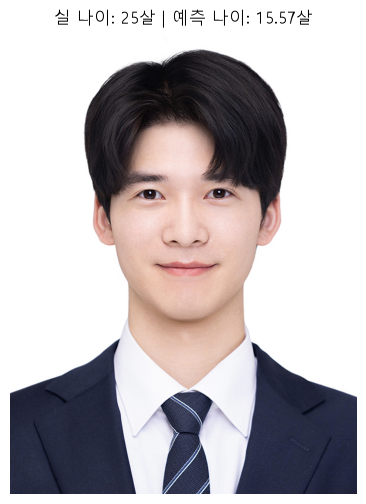

In [40]:
img_path = r"D:\kdt_dataset\machine_learning\park.jpg"
img = Image.open(img_path).convert("RGB")
img_tensor = test_transform(img)
img_batch = img_tensor.unsqueeze(0).to(device)

model3.eval()
with torch.no_grad():
    output = model3(img_batch)
    predicted_age = output.item()

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"실 나이: {25}살 | 예측 나이: {predicted_age:.2f}살")
plt.show()